# **Mini-Assignment 2** (Elisa Bucci)

Task:

i) Consider the average $\bar{X}$ of an $n$-sample of independent, identically Poisson-distributed random variables $X_1, \ldots, X_n$ with $\mathbb{E}[X_i] = 3$. Using an adequate test for goodness-of-fit, determine whether samples of sizes $50$, $100$, $200$, $1000$, $10000$ are large enough to safely consider $\bar{X}$ as approximately normally distributed.

ii) Consider the average $\bar{X}$ of an $n-$sample of independent, identically Bernoulli-distributed random variables $X_1, \ldots, X_n$ with $\mathbb{E}[X_i] = 0.02$. Using an adequate test for goodness-of-fit, determine whether samples of sizes $100$, $500$, $1000$, $10000$, $50000$, $100000$ are large enough to safely consider $\bar{X}$ as approximately normally distributed.

For each sample size $n$, I simulate $N$ independent $n$-samples and I compute $\bar{X}$ for each of them, this yields $N$ simulated values approximating the sampling distribution of $\bar{X}$. Then I test $H_0$: "$\bar{X}$ is normally distributed" using `sp.stats.normaltest`, and I combined sample skewness and kurtosis into a single statistic and compared the empirical density of $\bar{X}$ to a fitted normal density.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy as sp

## i) Average of Poisson-distributed random variables

From theory the sum of $n$ independent $\mathcal{P}(\lambda)$ poisson random variables is itself a $\mathcal{P}(n\lambda)$ Poisson distribution. So, instead of generating the $n$ individual $X_i$'s for every one of the $N$ replicated samples, cause it woild be an $n \times N$ array that would become very large for $n=10000$, we can draw $\bar X = \dfrac{1}{n}\mathcal{P}(n\lambda)$ directly.

In [2]:
np.random.seed(12345) # Setting a seed for reproducibility.

lam = 3     # E[X_i] = lambda = 3
N = 10000   # number of replicated n-samples used to approximate the sampling distribution of X-bar.
sample_sizes = [50, 100, 200, 1000, 10000]

xbars_poisson = {}    # array with the N simulated values of X-bar.
results_poisson = []  # goodness-of-fit test results for each n.

for n in sample_sizes:
    xbar = np.random.poisson(lam=n * lam, size=N) / n # X-bar of an n-sample of iid Poisson(lam) variables.
    xbars_poisson[n] = xbar

    skewness = sp.stats.skew(xbar)     # sample skewness (0 for an exactly normal distribution)
    kurtosis = sp.stats.kurtosis(xbar) # sample excess kurtosis (0 for an exactly normal distribution)
    stat, p_value = sp.stats.normaltest(xbar) # D'Agostino-Pearson test of normality

    results_poisson.append({'n': n, 'mean(xbar)': xbar.mean(), 'sd(xbar)': xbar.std(ddof=1),
                             'skewness': skewness, 'excess kurtosis': kurtosis,
                             'statistic': stat, 'p_value': p_value})

results_poisson_df = pd.DataFrame(results_poisson)
results_poisson_df['reject H0 at 5%?'] = results_poisson_df['p_value'] < .05
results_poisson_df

,n,mean(xbar),sd(xbar),skewness,excess kurtosis,statistic,p_value,reject H0 at 5%?
0,50,2.998790,0.245896,0.091462,0.012879,13.993932,0.000915,True
1,100,3.000115,0.174233,0.017044,-0.043878,1.259319,0.532773,False
2,200,3.000838,0.122830,0.070886,-0.007945,8.382350,0.015129,True
3,1000,3.000433,0.055232,0.031324,-0.037760,2.199078,0.333025,False
4,10000,2.999833,0.017442,0.013750,0.004646,0.332828,0.846696,False


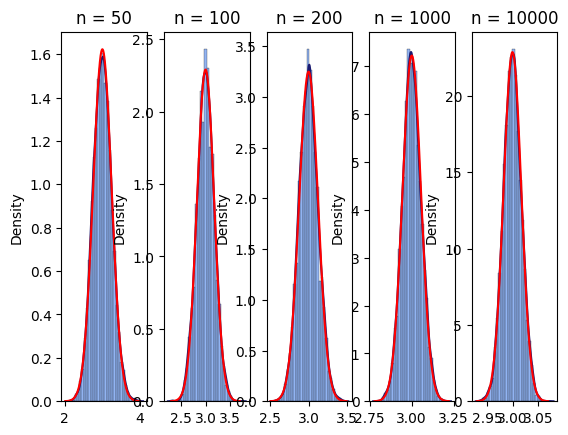

In [3]:
fig, ax = plt.subplots(1, 5)
plt.rcParams["figure.figsize"] = [20, 3]
plt.rcParams["figure.autolayout"] = True

for i, n in enumerate(sample_sizes):
    xbar = xbars_poisson[n]
    mu_x, sigma_x = xbar.mean(), xbar.std(ddof=1)

    # Empirical density of X-bar.
    sns.histplot(x=xbar, stat='density', bins=30, alpha=.7, color='cornflowerblue', ax=ax[i])
    sns.kdeplot(x=xbar, color='midnightblue', ax=ax[i])

    # Fitted normal density (same mean/sd as the empirical sample of X-bar).
    x_values = mu_x + np.arange(-4 * sigma_x, 4 * sigma_x, sigma_x / 100)
    y_values = sp.stats.norm.pdf(x=x_values, loc=mu_x, scale=sigma_x)
    sns.lineplot(x=x_values, y=y_values, color='red', ax=ax[i])
    ax[i].set_title(f'n = {n}')

The null-hypothesis is the event $H_0$: "$\bar X$ is normally distributed." Poisson $(\lambda=3)$ is only mildly skewed (population skewness $=1/\sqrt{\lambda}\approx 0.577$), so the skewness of $\bar X$ that is theoretically $1/\sqrt{n\lambda}$ is already small even at $n=50$ ($\approx 0.08$) and keeps lowering as $n$ grows. Visually, the histogram of $\bar X$ hugs the fitted normal curve closely at every one of the tested sizes. The individual `normaltest` decisions rejects at $n=50$ and $n=200$ and  fails to reject at $n=100$ and $n=1000$. The skewness/kurtosis column shrinks toward $0$ so $\bar X$ is already safely close to normal from $n=50$ onward and indistinguishable from normal by $n=1000$ or $10000$.

## ii) Average of Bernoulli-distributed random variables 

From the theory the sum of $n$ independent $\mathcal{B}(p)$ Bernoulli random variables is $\mathcal{B}(n,p)$ a Binomial distribution. So we draw $\bar X = \dfrac{1}{n}\mathcal{B}(n,p)$ directly, for the same reason as before.

In [4]:
np.random.seed(12345) # seed for reproducibility

p = 0.02     # E[X_i] = p = 0.02 for the Bernoulli population
N = 10000    # number of replicated n-samples used to approximate the sampling distribution of X-bar
sample_sizes = [100, 500, 1000, 10000, 50000, 100000]

xbars_bernoulli = {}    # array with the N simulated values of X-bar.
results_bernoulli = []  # goodness-of-fit test results for each n.

for n in sample_sizes:
    xbar = np.random.binomial(n=n, p=p, size=N) / n # X-bar of an n-sample of iid Bernoulli(p) variables.
    xbars_bernoulli[n] = xbar

    skewness = sp.stats.skew(xbar)
    kurtosis = sp.stats.kurtosis(xbar)
    stat, p_value = sp.stats.normaltest(xbar)

    results_bernoulli.append({'n': n, 'mean(xbar)': xbar.mean(), 'sd(xbar)': xbar.std(ddof=1),
                               'n*p': n * p, 'n*(1-p)': n * (1 - p), # rule-of-thumb quantities.
                               'skewness': skewness, 'excess kurtosis': kurtosis,
                               'statistic': stat, 'p_value': p_value})

results_bernoulli_df = pd.DataFrame(results_bernoulli)
results_bernoulli_df['reject H0 at 5%?'] = results_bernoulli_df['p_value'] < .05
results_bernoulli_df

,n,mean(xbar),sd(xbar),n*p,n*(1-p),skewness,excess kurtosis,statistic,p_value,reject H0 at 5%?
0,100,0.020149,0.014000,2.0,98.0,0.647353,0.284046,614.797538,3.150728e-134,True
1,500,0.020047,0.006319,10.0,490.0,0.341133,0.146487,191.908832,2.125821e-42,True
2,1000,0.020004,0.004434,20.0,980.0,0.237848,-0.003741,91.878071,1.119259e-20,True
3,10000,0.020003,0.001402,200.0,9800.0,0.096631,0.046141,16.432455,2.702325e-04,True
4,50000,0.020003,0.000626,1000.0,49000.0,-0.030104,0.036673,2.108918,3.483809e-01,False
5,100000,0.020000,0.000444,2000.0,98000.0,0.012464,0.021527,0.481954,7.858596e-01,False


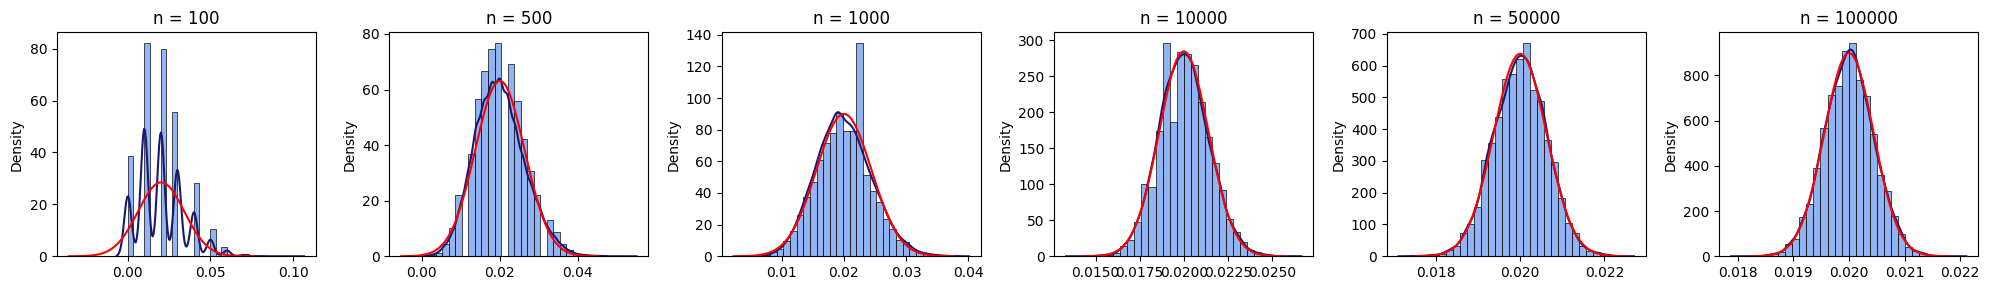

In [5]:
fig, ax = plt.subplots(1, 6)
plt.rcParams["figure.figsize"] = [22, 3]
plt.rcParams["figure.autolayout"] = True

for i, n in enumerate(sample_sizes):
    xbar = xbars_bernoulli[n]
    mu_x, sigma_x = xbar.mean(), xbar.std(ddof=1)

    sns.histplot(x=xbar, stat='density', bins=30, alpha=.7, color='cornflowerblue', ax=ax[i])
    sns.kdeplot(x=xbar, color='midnightblue', ax=ax[i])

    x_values = mu_x + np.arange(-4 * sigma_x, 4 * sigma_x, sigma_x / 100)
    y_values = sp.stats.norm.pdf(x=x_values, loc=mu_x, scale=sigma_x)
    sns.lineplot(x=x_values, y=y_values, color='red', ax=ax[i])
    ax[i].set_title(f'n = {n}')

Here the pictures are different wrt n. Bernoulli with $(p=0.02)$ is a rare-event population, heavily right-skewed (population skewness $=\dfrac{1-2p}{\sqrt{p(1-p)}}\approx 6.86$) and $\bar X$ inherits that skewness at small $n$. As $n$ grows to $500$, $1000$, then $10000$ (i.e. $n p = 10, 20, 200$) the skewness is much more low but is still statistically detectable at $n=10000$ ($p\approx 0.0003$). Only from $n=50000$ onward ($np=1000$) does the skewness become small enough ($\approx 0.01-0.03$ in absolute value) that `normaltest` no longer rejects $H_0$ ($p\approx 0.35-0.79$) and the histogram now overlays the fitted normal density closely. So because $p=0.02$ is so small, samples need to be considerably larger for the Bernoulli case than for the Poisson case before $\bar X$ can be safely treated as approximately normal, only comfortably safe from around $n=50000$ onward.